In [1]:
# importing
# import libraries
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# from sklearn.datasets import load_boston
# from fairlearn.datasets import fetch_boston

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import RocCurveDisplay,f1_score,classification_report,confusion_matrix, recall_score, precision_score

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer

import category_encoders as ce

import warnings
warnings.filterwarnings('ignore')

In [2]:
# import dataset
bankloan = pd.read_csv('Dataset/bankloan.csv')
bankloan.head()

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1
1,27,1,10,6,31,17.3,1.362202,4.000798,0
2,40,1,15,14,55,5.5,0.856075,2.168925,0
3,41,1,15,14,120,2.9,2.658720,0.821280,0
4,24,2,2,0,28,17.3,1.787436,3.056564,1


In [3]:
# feature selection
features = ['employ','debtinc','creddebt','othdebt']
target = ['default']

X = bankloan[features]
y = bankloan[target]

In [7]:
# data split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 2020
)

In [8]:
# prepare all the model
logreg = LogisticRegression(solver='liblinear', random_state=2020)
knn = KNeighborsClassifier(n_neighbors=3)
tree = DecisionTreeClassifier(criterion='entropy',max_depth=3)

In [9]:
# define the fold for Cross-Validation
skfold = StratifiedKFold(n_splits= 5)

logreg_cv = cross_val_score(estimator=logreg, X=X_train_val
                        , y =y_train_val,cv=skfold)
knn_cv = cross_val_score(estimator=knn, X=X_train_val,y=y_train_val, cv=skfold)
tree_cv = cross_val_score(estimator=tree, X=X_train_val,y=y_train_val, cv=skfold)


In [10]:
# print the validation_score
print('CV for logreg:', logreg_cv)
print('CV for knn:', knn_cv)
print('CV for tree:', tree_cv)

CV for logreg: [0.77678571 0.71428571 0.77678571 0.88392857 0.82142857]
CV for knn: [0.72321429 0.70535714 0.75       0.70535714 0.76785714]
CV for tree: [0.75892857 0.72321429 0.78571429 0.75       0.76785714]


In [11]:
# print the validation_score mean as representative validation score
print('CV for logreg:', logreg_cv.mean(),',and the stand deviation: ,', logreg_cv.std())
print('CV for knn:', knn_cv.mean(),',and the stand deviation: ,', knn_cv.std())
print('CV for tree:', tree_cv.mean(),',and the stand deviation: ,', tree_cv.std())

CV for logreg: 0.7946428571428571 ,and the stand deviation: , 0.05618618829482953
CV for knn: 0.7303571428571429 ,and the stand deviation: , 0.024872121923543065
CV for tree: 0.7571428571428571 ,and the stand deviation: , 0.020671137326411123


In [16]:
# see the another evaluation metrics: recall
skfold = StratifiedKFold(n_splits= 5)

logreg_cv = cross_val_score(estimator=logreg, X=X_train_val
                        , y =y_train_val,cv=skfold, scoring='recall')
knn_cv = cross_val_score(estimator=knn, X=X_train_val,y=y_train_val, cv=skfold, scoring='recall')
tree_cv = cross_val_score(estimator=tree, X=X_train_val,y=y_train_val, cv=skfold, scoring='recall')


In [17]:
# print the validation recall score
print('CV for logreg:', logreg_cv)
print('CV for knn:', knn_cv)
print('CV for tree:', tree_cv)

CV for logreg: [0.35714286 0.51724138 0.31034483 0.65517241 0.4137931 ]
CV for knn: [0.32142857 0.48275862 0.34482759 0.37931034 0.34482759]
CV for tree: [0.46428571 0.55172414 0.34482759 0.13793103 0.10344828]


In [18]:
# print the validation recall score mean as representative validation score
print('CV for logreg:', logreg_cv.mean(),',and the stand deviation: ,', logreg_cv.std())
print('CV for knn:', knn_cv.mean(),',and the stand deviation: ,', knn_cv.std())
print('CV for tree:', tree_cv.mean(),',and the stand deviation: ,', tree_cv.std())
# std for calculate distance so the less the stable

CV for logreg: 0.45073891625615764 ,and the stand deviation: , 0.12332992175989038
CV for knn: 0.37463054187192124 ,and the stand deviation: , 0.05713223954356393
CV for tree: 0.3204433497536946 ,and the stand deviation: , 0.17616675459364586


In [19]:
# see the another evaluation metrics : precision
skfold = StratifiedKFold(n_splits= 5)

logreg_cv = cross_val_score(estimator=logreg, X=X_train_val, y =y_train_val,cv=skfold, scoring='precision')
knn_cv = cross_val_score(estimator=knn, X=X_train_val,y=y_train_val, cv=skfold, scoring='precision')
tree_cv = cross_val_score(estimator=tree, X=X_train_val,y=y_train_val, cv=skfold, scoring='precision')


In [20]:
# print the validation precision score
print('CV for logreg:', logreg_cv)
print('CV for knn:', knn_cv)
print('CV for tree:', tree_cv)

CV for logreg: [0.58823529 0.45454545 0.64285714 0.86363636 0.8       ]
CV for knn: [0.42857143 0.4375     0.52631579 0.42307692 0.58823529]
CV for tree: [0.52       0.47058824 0.66666667 0.57142857 1.        ]


In [23]:
# model perfomance in Test: logreg
logreg.fit(X_train_val,y_train_val)
y_pred = logreg.predict(X_test)

# show the evaluation metrics
print('recall: ', recall_score(y_test,y_pred))
print('precision: ', precision_score(y_test,y_pred))
print('f1-score: ', f1_score(y_test,y_pred))


recall:  0.5384615384615384
precision:  0.7241379310344828
f1-score:  0.6176470588235294


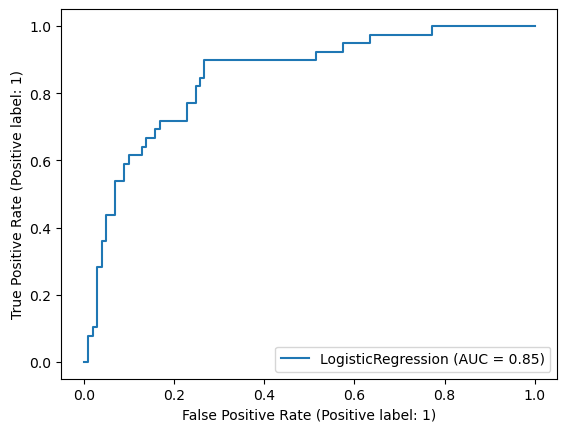

In [24]:
# plot the ROC Curve
RocCurveDisplay.from_estimator(logreg, X_test, y_test)

In [41]:
X = bankloan[features]
y = bankloan[target]

In [42]:
# first split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 2020
)

In [43]:
# Simple Parameter Tuning
# second split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size= 0.2,
    random_state= 2020
)

In [44]:
# Regualrization with C
hyperparam_c = [1000,500,100,50,10,5,1,0.1,0.5,0.01,0.05,0.001,0.005]
skfold = StratifiedKFold(n_splits=5)

best_score = 0
cv_score_validation_fold = []

for i in hyperparam_c:
    logreg = LogisticRegression(C=i, solver='liblinear', random_state=2020)
    cv_score = cross_val_score(logreg, X_train_val, y_train_val, cv=skfold, scoring='f1').mean()
    cv_score_validation_fold.append(cv_score)

    if cv_score > best_score:
        best_score = cv_score
        best_params = {'C':i}

In [45]:
# show best cv and params
print('best f1 score:', best_score)
print('best_params: ',best_params)

best f1 score: 0.5546664724164725
best_params:  {'C': 0.1}
